In [10]:
!pip install ultralytics fastapi uvicorn python-multipart httpx pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 23.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [11]:
import torch
import io
import json
import uuid

from datetime import datetime
from collections import Counter
from PIL import Image
from ultralytics import YOLO
from fastapi import FastAPI, UploadFile, File, HTTPException
from fastapi.testclient import TestClient
from google.colab import files
from IPython.display import display

if torch.cuda.is_available():
    device = "cuda:0"
    print("GPU is available!")
else:
    device = "cpu"
    print("Using CPU.")

print("Selected device:", device)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Using CPU.
Selected device: cpu


In [12]:
model = YOLO("yolo11n.pt")

print("VisionPort YOLO11 Model Loaded Successfully!")
print("Model: YOLO11n")
print("Device:", device)


VisionPort YOLO11 Model Loaded Successfully!
Model: YOLO11n
Device: cpu


In [13]:
app = FastAPI(
    title="VisionPort Inference Request Trace API",
    description="API Input, Preprocessing, Model Execution and Response"
)

print("VisionPort Inference API Created Successfully!")


VisionPort Inference API Created Successfully!


In [14]:
@app.post("/trace")
async def inference_trace(file: UploadFile = File(...)):

    request_id = str(uuid.uuid4())

    print("\n========== API INPUT ==========")

    print("Request ID:", request_id)
    print("Filename:", file.filename)
    print("Content Type:", file.content_type)

    if not file.content_type or not file.content_type.startswith("image/"):
        raise HTTPException(
            status_code=400,
            detail="Please upload a valid image"
        )

    try:
        image_bytes = await file.read()

        print("\n========== PREPROCESSING ==========")

        image = Image.open(
            io.BytesIO(image_bytes)
        )

        print("Original Format:", image.format)
        print("Original Size:", image.size)

        processed_image = image.convert("RGB")

        print("Converted Format: RGB")
        print("Processed Size:", processed_image.size)

        print("\n========== MODEL EXECUTION ==========")

        results = model.predict(
            source=processed_image,
            conf=0.25,
            device=device
        )

        result = results[0]

        detections = []

        for box in result.boxes:

            class_id = int(box.cls[0])
            object_name = result.names[class_id]
            confidence = float(box.conf[0])
            coordinates = box.xyxy[0].tolist()

            detections.append({
                "object": object_name,
                "confidence": round(confidence * 100, 2),
                "bounding_box": [
                    round(value, 2)
                    for value in coordinates
                ]
            })

        object_counts = dict(
            Counter(
                item["object"]
                for item in detections
            )
        )

        print("Model:", "YOLO11n")
        print("Total Objects:", len(detections))

        print("\n========== API RESPONSE ==========")

        response = {
            "request_id": request_id,
            "status": "success",
            "filename": file.filename,
            "model": "YOLO11n",
            "preprocessing": {
                "format": "RGB",
                "image_size": list(processed_image.size)
            },
            "total_objects": len(detections),
            "object_counts": object_counts,
            "detections": detections,
            "timestamp": datetime.now().isoformat()
        }

        print(json.dumps(response, indent=4))

        return response

    except HTTPException:
        raise

    except Exception as e:
        raise HTTPException(
            status_code=400,
            detail=f"Unable to process image: {str(e)}"
        )

print("Inference Trace Endpoint Created Successfully!")
print("Endpoint: POST /trace")


Inference Trace Endpoint Created Successfully!
Endpoint: POST /trace


In [15]:
client = TestClient(app)

print("API Test Client Created Successfully!")
print("Ready to Send Inference Requests!")


API Test Client Created Successfully!
Ready to Send Inference Requests!


In [16]:
print("========== UPLOAD IMAGE ==========")

uploaded = files.upload()

filename = next(iter(uploaded.keys()))

print("Image Uploaded:", filename)

print("\n========== SENDING API REQUEST ==========")

response = client.post(
    "/trace",
    files={
        "file": (
            filename,
            uploaded[filename],
            "image/jpeg"
        )
    }
)

print("\nHTTP Status Code:", response.status_code)

data = response.json()

print("\nAPI Request Completed!")


========== UPLOAD IMAGE ==========


Saving images (3).jpg to images (3).jpg
Image Uploaded: images (3).jpg

========== SENDING API REQUEST ==========

========== API INPUT ==========
Request ID: c5173825-d2a9-4a57-9ca0-370a86e2eafa
Filename: images (3).jpg
Content Type: image/jpeg

========== PREPROCESSING ==========
Original Format: JPEG
Original Size: (718, 426)
Converted Format: RGB
Processed Size: (718, 426)

========== MODEL EXECUTION ==========

0: 384x640 7 persons, 3 cars, 9 traffic lights, 1 backpack, 381.7ms
Speed: 28.4ms preprocess, 381.7ms inference, 38.5ms postprocess per image at shape (1, 3, 384, 640)
Model: YOLO11n
Total Objects: 20

========== API RESPONSE ==========
{
    "request_id": "c5173825-d2a9-4a57-9ca0-370a86e2eafa",
    "status": "success",
    "filename": "images (3).jpg",
    "model": "YOLO11n",
    "preprocessing": {
        "format": "RGB",
        "image_size": [
            718,
            426
        ]
    },
    "total_objects": 20,
    "object_counts": {
        "person": 7,
        "

In [17]:

print("========== FINAL API RESPONSE ==========")

print(json.dumps(data, indent=4))


========== FINAL API RESPONSE ==========
{
    "request_id": "c5173825-d2a9-4a57-9ca0-370a86e2eafa",
    "status": "success",
    "filename": "images (3).jpg",
    "model": "YOLO11n",
    "preprocessing": {
        "format": "RGB",
        "image_size": [
            718,
            426
        ]
    },
    "total_objects": 20,
    "object_counts": {
        "person": 7,
        "car": 3,
        "traffic light": 9,
        "backpack": 1
    },
    "detections": [
        {
            "object": "person",
            "confidence": 91.54,
            "bounding_box": [
                292.77,
                147.15,
                392.97,
                386.52
            ]
        },
        {
            "object": "person",
            "confidence": 85.31,
            "bounding_box": [
                204.13,
                158.12,
                236.15,
                254.58
            ]
        },
        {
            "object": "person",
            "confidence": 84.01,
     

In [18]:
print("========== DETECTION SUMMARY ==========")

print("Filename:", data["filename"])
print("Model:", data["model"])
print("Total Objects:", data["total_objects"])

print("\nObject Counts:")

for name, count in data["object_counts"].items():
    print(name, ":", count)

print("\nIndividual Detections:")

for detection in data["detections"]:
    print(detection)


========== DETECTION SUMMARY ==========
Filename: images (3).jpg
Model: YOLO11n
Total Objects: 20

Object Counts:
person : 7
car : 3
traffic light : 9
backpack : 1

Individual Detections:
{'object': 'person', 'confidence': 91.54, 'bounding_box': [292.77, 147.15, 392.97, 386.52]}
{'object': 'person', 'confidence': 85.31, 'bounding_box': [204.13, 158.12, 236.15, 254.58]}
{'object': 'person', 'confidence': 84.01, 'bounding_box': [445.41, 154.6, 520.61, 367.09]}
{'object': 'person', 'confidence': 80.59, 'bounding_box': [71.69, 148.66, 149.17, 385.21]}
{'object': 'person', 'confidence': 79.88, 'bounding_box': [598.89, 144.73, 676.11, 381.47]}
{'object': 'car', 'confidence': 72.7, 'bounding_box': [0.12, 208.36, 102.2, 267.43]}
{'object': 'traffic light', 'confidence': 68.39, 'bounding_box': [605.56, 96.02, 628.71, 145.77]}
{'object': 'person', 'confidence': 66.55, 'bounding_box': [657.8, 173.34, 710.18, 380.62]}
{'object': 'person', 'confidence': 64.77, 'bounding_box': [495.43, 168.75, 516.8

========== DETECTION VISUALIZATION ==========

image 1/1 /content/images (3).jpg: 384x640 7 persons, 3 cars, 9 traffic lights, 1 backpack, 139.8ms
Speed: 5.3ms preprocess, 139.8ms inference, 1.7ms postprocess per image at shape (1, 3, 384, 640)


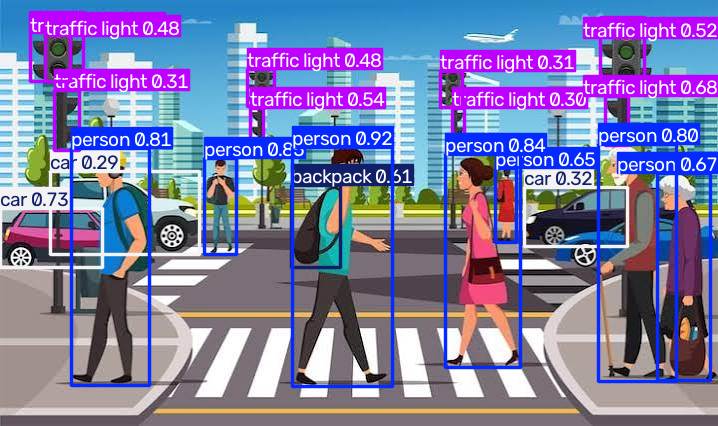

Detection Visualization Completed!


In [19]:
print("========== DETECTION VISUALIZATION ==========")

results = model.predict(
    source=filename,
    conf=0.25,
    device=device
)

annotated_image = results[0].plot()

display(
    Image.fromarray(annotated_image[:, :, ::-1])
)

print("Detection Visualization Completed!")


In [20]:
print("==========================================")
print("       VISIONPORT INFERENCE REQUEST TRACE")
print("==========================================")

print("\n1. API INPUT")
print("Request ID:", data["request_id"])
print("Filename:", data["filename"])

print("\n2. PREPROCESSING")
print("Image Format:", data["preprocessing"]["format"])
print("Image Size:", data["preprocessing"]["image_size"])

print("\n3. MODEL EXECUTION")
print("Model:", data["model"])
print("Total Objects:", data["total_objects"])

print("\n4. API RESPONSE")
print("Status:", data["status"])
print("Object Counts:", data["object_counts"])

print("\n==========================================")
print("INFERENCE REQUEST TRACE COMPLETED!")
print("==========================================")


       VISIONPORT INFERENCE REQUEST TRACE

1. API INPUT
Request ID: c5173825-d2a9-4a57-9ca0-370a86e2eafa
Filename: images (3).jpg

2. PREPROCESSING
Image Format: RGB
Image Size: [718, 426]

3. MODEL EXECUTION
Model: YOLO11n
Total Objects: 20

4. API RESPONSE
Status: success
Object Counts: {'person': 7, 'car': 3, 'traffic light': 9, 'backpack': 1}

INFERENCE REQUEST TRACE COMPLETED!
